<a href="https://colab.research.google.com/github/beyonddbold-ux/ML-Models/blob/main/02_09_2026_Portfolio_Allocation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MBA Portfolio Allocation Using Real Stock Market Data
You are managing a ₹10,00,000 equity portfolio. How should the money be allocated across selected stocks to balance return and risk?

This notebook uses Indian stock-market data and demonstrates the complete workflow:
1. Download prices
2. Calculate returns
3. Measure risk
4. Study correlation
5. Build portfolios
6. Simulate thousands of portfolios
7. Identify Minimum Variance and Maximum Sharpe Ratio portfolios
8. Make an investment recommendation


## 1. Install and import libraries
Run the installation command only if the required libraries are not already installed.


In [1]:
# Uncomment if required
# !pip install yfinance pandas numpy matplotlib


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 2. Select the investment universe
You may replace these tickers with other NSE-listed stocks.

**Business question:** Which companies should be included in the investment universe, and why?


In [3]:
tickers = {
    "Reliance": "RELIANCE.NS",
    "TCS": "TCS.NS",
    "HDFC Bank": "HDFCBANK.NS",
    "Infosys": "INFY.NS",
    "ITC": "ITC.NS",
    "Sun Pharma": "SUNPHARMA.NS"
}

ticker_list = list(tickers.values())
ticker_list


['RELIANCE.NS', 'TCS.NS', 'HDFCBANK.NS', 'INFY.NS', 'ITC.NS', 'SUNPHARMA.NS']

## 3. Download historical stock prices
Choose a period long enough to observe meaningful return behaviour.


In [4]:
start_date = "2023-01-01"
end_date = None  # None uses the latest available data

prices = yf.download(
    ticker_list,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)["Close"]

prices.columns = tickers.keys()
prices = prices.dropna()

print("Dataset shape:", prices.shape)
prices.head()


Dataset shape: (909, 6)


,Reliance,TCS,HDFC Bank,Infosys,ITC,Sun Pharma
Date,,,,,,
2023-01-02,770.9272,"1,368.0974",274.9213,"1,170.4780",959.5864,"2,877.7810"
2023-01-03,775.9683,"1,366.7958",273.4759,"1,161.9126",971.2323,"2,921.8115"
2023-01-04,762.0995,"1,341.8845",270.0894,"1,144.4182",966.4199,"2,924.7224"
2023-01-05,757.2003,"1,324.2896",275.4168,"1,142.3734",978.0659,"2,921.5908"
2023-01-06,754.6917,"1,300.3210",276.7384,"1,152.7563",970.8474,"2,833.7515"


## 4. Visualise stock prices
**Business question:** How have the selected stocks performed historically?


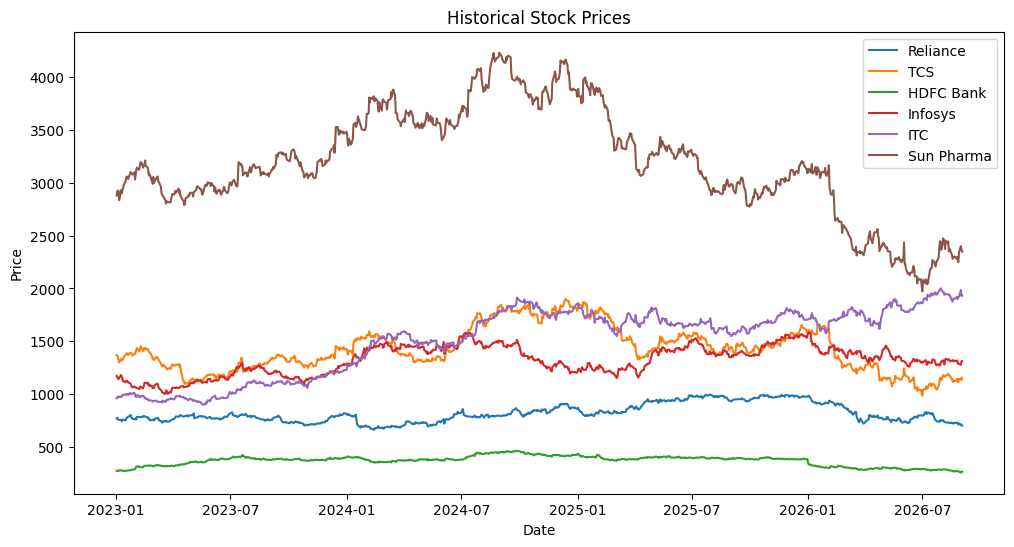

In [5]:
plt.figure(figsize=(12, 6))
for stock in prices.columns:
    plt.plot(prices.index, prices[stock], label=stock)

plt.title("Historical Stock Prices")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.show()


## 5. Calculate daily returns
Daily return = (Price today - Price yesterday) / Price yesterday.

**Business question:** Which stocks generated stronger historical returns?


In [6]:
daily_returns = prices.pct_change().dropna()
daily_returns.head()


,Reliance,TCS,HDFC Bank,Infosys,ITC,Sun Pharma
Date,,,,,,
2023-01-03,0.0065,-0.0010,-0.0053,-0.0073,0.0121,0.0153
2023-01-04,-0.0179,-0.0182,-0.0124,-0.0151,-0.0050,0.0010
2023-01-05,-0.0064,-0.0131,0.0197,-0.0018,0.0121,-0.0011
2023-01-06,-0.0033,-0.0181,0.0048,0.0091,-0.0074,-0.0301
2023-01-09,0.0019,0.0248,0.0090,0.0236,0.0081,0.0338


## 6. Annualised return and risk
Assumption: approximately 252 trading days per year.

- Annualised return = average daily return × 252
- Annualised volatility = daily standard deviation × √252

**Business question:** Which stocks have higher return, and which have higher risk?


In [7]:
trading_days = 252

annual_returns = daily_returns.mean() * trading_days
annual_volatility = daily_returns.std() * np.sqrt(trading_days)

stock_summary = pd.DataFrame({
    "Annual Return": annual_returns,
    "Annual Volatility": annual_volatility
}).sort_values("Annual Return", ascending=False)

stock_summary


,Annual Return,Annual Volatility
ITC,0.2121,0.1890
Infosys,0.0529,0.2054
HDFC Bank,0.0086,0.1864
Reliance,-0.0070,0.1971
TCS,-0.0176,0.2569
Sun Pharma,-0.0311,0.2254


## 7. Risk-return comparison
A good investment decision should consider both return and risk, not return alone.


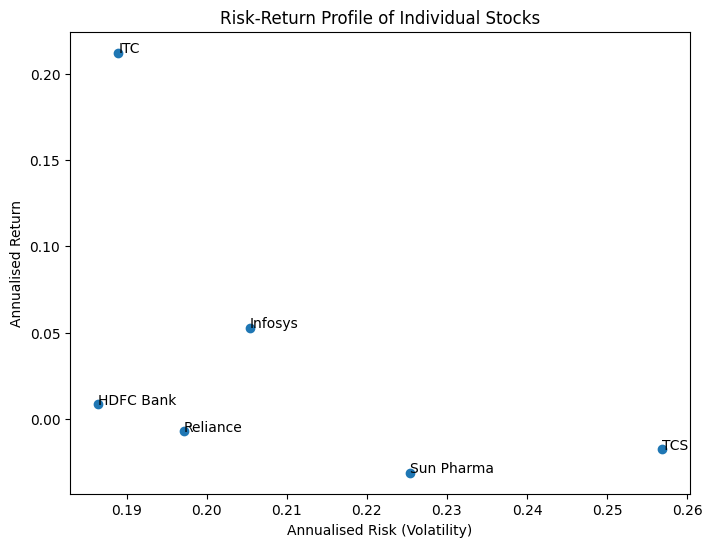

In [8]:
plt.figure(figsize=(8, 6))
plt.scatter(stock_summary["Annual Volatility"], stock_summary["Annual Return"])

for stock in stock_summary.index:
    plt.annotate(
        stock,
        (stock_summary.loc[stock, "Annual Volatility"],
         stock_summary.loc[stock, "Annual Return"])
    )

plt.title("Risk-Return Profile of Individual Stocks")
plt.xlabel("Annualised Risk (Volatility)")
plt.ylabel("Annualised Return")
plt.show()


## 8. Correlation analysis
Correlation shows whether stocks tend to move together.

**Business question:** Does combining these stocks provide diversification benefits?


In [9]:
correlation = daily_returns.corr()
correlation


,Reliance,TCS,HDFC Bank,Infosys,ITC,Sun Pharma
Reliance,1.0000,0.1910,0.1938,0.3765,0.1157,0.1680
TCS,0.1910,1.0000,0.1452,0.2256,0.1379,0.7340
HDFC Bank,0.1938,0.1452,1.0000,0.2918,0.1388,0.1646
Infosys,0.3765,0.2256,0.2918,1.0000,0.2372,0.2305
ITC,0.1157,0.1379,0.1388,0.2372,1.0000,0.1786
Sun Pharma,0.1680,0.7340,0.1646,0.2305,0.1786,1.0000


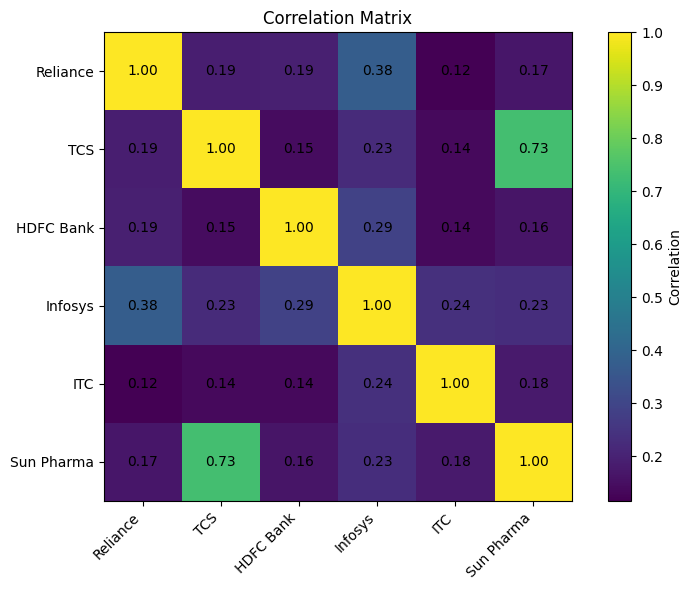

In [10]:
plt.figure(figsize=(8, 6))
plt.imshow(correlation.values)
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.index)), correlation.index)
plt.colorbar(label="Correlation")
plt.title("Correlation Matrix")

for i in range(len(correlation.index)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center")

plt.tight_layout()
plt.show()


## 9. Create an equal-weight portfolio
This is the simplest benchmark portfolio.

**Business question:** What happens if the ₹10,00,000 is divided equally among all selected stocks?


In [11]:
n_assets = len(daily_returns.columns)
equal_weights = np.repeat(1 / n_assets, n_assets)

portfolio_return_equal = np.sum(equal_weights * annual_returns)
portfolio_risk_equal = np.sqrt(
    np.dot(equal_weights.T, np.dot(daily_returns.cov() * trading_days, equal_weights))
)

print("Equal-weight portfolio annual return:", portfolio_return_equal)
print("Equal-weight portfolio annual risk:", portfolio_risk_equal)

allocation_equal = pd.DataFrame({
    "Stock": daily_returns.columns,
    "Weight": equal_weights,
    "Investment (₹)": equal_weights * 1_000_000
})
allocation_equal


Equal-weight portfolio annual return: 0.03632280531588577
Equal-weight portfolio annual risk: 0.12832515650693752


,Stock,Weight,Investment (₹)
0,Reliance,0.1667,"166,666.6667"
1,TCS,0.1667,"166,666.6667"
2,HDFC Bank,0.1667,"166,666.6667"
3,Infosys,0.1667,"166,666.6667"
4,ITC,0.1667,"166,666.6667"
5,Sun Pharma,0.1667,"166,666.6667"


## 10. Simulate thousands of possible portfolios
Each simulation creates a different set of portfolio weights.

**Business question:** Among thousands of possible allocations, which portfolios offer attractive combinations of risk and return?


In [12]:
np.random.seed(42)

n_portfolios = 10000
results = np.zeros((3, n_portfolios))
weights_record = []

cov_matrix = daily_returns.cov() * trading_days

for i in range(n_portfolios):
    weights = np.random.random(n_assets)
    weights = weights / np.sum(weights)
    weights_record.append(weights)

    p_return = np.sum(weights * annual_returns)
    p_risk = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    sharpe = p_return / p_risk  # simplified; risk-free rate added later

    results[0, i] = p_return
    results[1, i] = p_risk
    results[2, i] = sharpe

portfolio_results = pd.DataFrame(results.T, columns=["Return", "Risk", "Sharpe Ratio"])
portfolio_results.head()


,Return,Risk,Sharpe Ratio
0,0.0158,0.1407,0.1123
1,0.0004,0.1585,0.0024
2,0.0223,0.1329,0.1678
3,0.0258,0.1257,0.2053
4,0.0525,0.1353,0.3879


## 11. Visualise simulated portfolios
The chart shows the risk-return choices available to the investor.


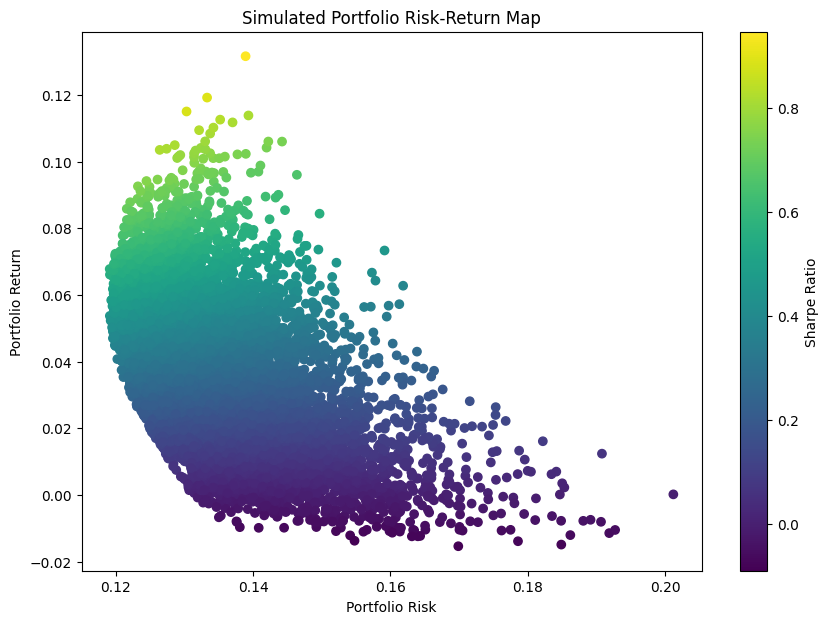

In [13]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    portfolio_results["Risk"],
    portfolio_results["Return"],
    c=portfolio_results["Sharpe Ratio"]
)
plt.colorbar(scatter, label="Sharpe Ratio")
plt.title("Simulated Portfolio Risk-Return Map")
plt.xlabel("Portfolio Risk")
plt.ylabel("Portfolio Return")
plt.show()


## 12. Identify the Minimum Variance Portfolio
This portfolio has the lowest estimated risk among the simulated portfolios.

**Business question:** How should a conservative investor allocate the ₹10,00,000?


In [14]:
min_var_index = portfolio_results["Risk"].idxmin()
min_var_weights = weights_record[min_var_index]

min_var_allocation = pd.DataFrame({
    "Stock": daily_returns.columns,
    "Weight": min_var_weights,
    "Investment (₹)": min_var_weights * 1_000_000
})

print("Minimum Variance Portfolio")
print("Expected annual return:", portfolio_results.loc[min_var_index, "Return"])
print("Annual risk:", portfolio_results.loc[min_var_index, "Risk"])
min_var_allocation


Minimum Variance Portfolio
Expected annual return: 0.06776285815391712
Annual risk: 0.11910219857026723


,Stock,Weight,Investment (₹)
0,Reliance,0.2016,"201,642.1087"
1,TCS,0.0209,"20,908.0437"
2,HDFC Bank,0.2738,"273,807.5448"
3,Infosys,0.0611,"61,070.3175"
4,ITC,0.3196,"319,619.6362"
5,Sun Pharma,0.1230,"122,952.3491"


## 13. Identify the Maximum Sharpe Ratio Portfolio
The Sharpe ratio measures return relative to risk.

For a more realistic analysis, we now allow the instructor to specify a risk-free rate.


In [15]:
risk_free_rate = 0.06  # Example assumption: 6%

portfolio_results["Sharpe Ratio RF"] = (
    (portfolio_results["Return"] - risk_free_rate)
    / portfolio_results["Risk"]
)

max_sharpe_index = portfolio_results["Sharpe Ratio RF"].idxmax()
max_sharpe_weights = weights_record[max_sharpe_index]

max_sharpe_allocation = pd.DataFrame({
    "Stock": daily_returns.columns,
    "Weight": max_sharpe_weights,
    "Investment (₹)": max_sharpe_weights * 1_000_000
})

print("Maximum Sharpe Ratio Portfolio")
print("Expected annual return:", portfolio_results.loc[max_sharpe_index, "Return"])
print("Annual risk:", portfolio_results.loc[max_sharpe_index, "Risk"])
print("Sharpe ratio:", portfolio_results.loc[max_sharpe_index, "Sharpe Ratio RF"])
max_sharpe_allocation


Maximum Sharpe Ratio Portfolio
Expected annual return: 0.1315888107058958
Annual risk: 0.13889809039483245
Sharpe ratio: 0.5154052910475375


,Stock,Weight,Investment (₹)
0,Reliance,0.0142,"14,197.9924"
1,TCS,0.0671,"67,070.2596"
2,HDFC Bank,0.1979,"197,874.3656"
3,Infosys,0.0653,"65,339.5119"
4,ITC,0.6091,"609,054.8094"
5,Sun Pharma,0.0465,"46,463.0610"


## 14. Compare the key portfolios
Compare:
- Equal-weight portfolio
- Minimum Variance Portfolio
- Maximum Sharpe Ratio Portfolio


In [16]:
comparison = pd.DataFrame({
    "Portfolio": [
        "Equal Weight",
        "Minimum Variance",
        "Maximum Sharpe Ratio"
    ],
    "Expected Return": [
        portfolio_return_equal,
        portfolio_results.loc[min_var_index, "Return"],
        portfolio_results.loc[max_sharpe_index, "Return"]
    ],
    "Risk": [
        portfolio_risk_equal,
        portfolio_results.loc[min_var_index, "Risk"],
        portfolio_results.loc[max_sharpe_index, "Risk"]
    ]
})

comparison["Sharpe Ratio (6% RF)"] = (
    (comparison["Expected Return"] - risk_free_rate) / comparison["Risk"]
)

comparison


,Portfolio,Expected Return,Risk,Sharpe Ratio (6% RF)
0,Equal Weight,0.0363,0.1283,-0.1845
1,Minimum Variance,0.0678,0.1191,0.0652
2,Maximum Sharpe Ratio,0.1316,0.1389,0.5154


## 15. Final visual comparison
**Business question:** Which portfolio should be recommended to the client?


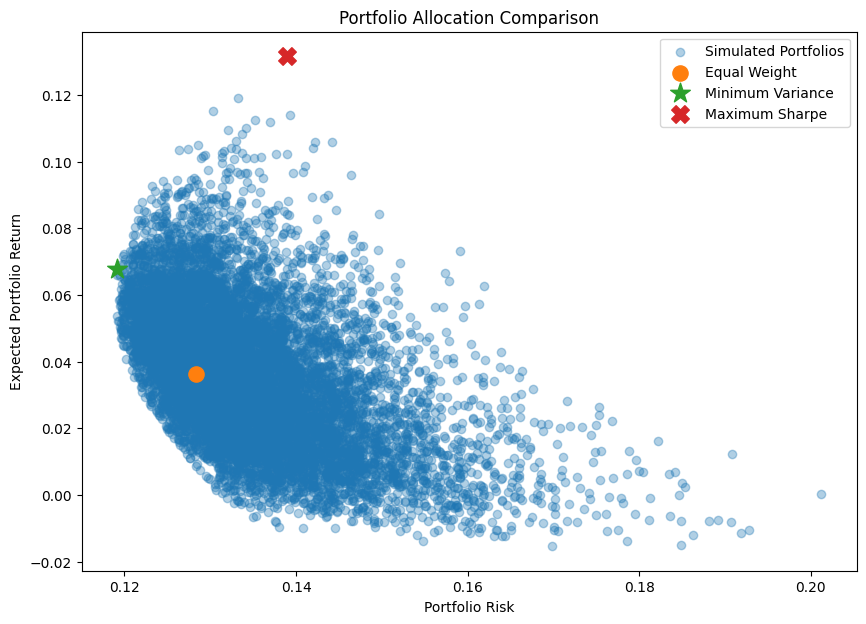

In [17]:
plt.figure(figsize=(10, 7))
plt.scatter(portfolio_results["Risk"], portfolio_results["Return"], alpha=0.35, label="Simulated Portfolios")

plt.scatter(
    portfolio_risk_equal,
    portfolio_return_equal,
    marker="o",
    s=120,
    label="Equal Weight"
)

plt.scatter(
    portfolio_results.loc[min_var_index, "Risk"],
    portfolio_results.loc[min_var_index, "Return"],
    marker="*",
    s=220,
    label="Minimum Variance"
)

plt.scatter(
    portfolio_results.loc[max_sharpe_index, "Risk"],
    portfolio_results.loc[max_sharpe_index, "Return"],
    marker="X",
    s=160,
    label="Maximum Sharpe"
)

plt.title("Portfolio Allocation Comparison")
plt.xlabel("Portfolio Risk")
plt.ylabel("Expected Portfolio Return")
plt.legend()
plt.show()
